In [1]:
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import harmonypy as hm
from trafficking_inference.CellVADIS import Stitch_OT, Joint_OT
from trafficking_inference.helper_functions import (
    plot_fate_probabilities_with_pie_charts,
)

plt.style.use("default")
np.random.seed(42)
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial"],
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "legend.fontsize": 6,
        "legend.frameon": False,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.figsize": (3.5, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": "standard",
        # "savefig.pad_inches": 0.02,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)


path_data = "data/TICA/"
use_stitchOT = True  # Wether to use StitchOT or JointOT for the analysis. If False, JointOT will be used.
if use_stitchOT:
    figure_path = "data/figures/TICA/StitchOT/StitchOT_"
else:
    figure_path = "data/figures/TICA/JointOT/JointOT_"
# load h5ad
adata = ad.read_h5ad(path_data + "t-cells.h5ad")


## Define tissue colors
# give each organ in obs a color from a colormap
cmap = plt.get_cmap("tab20")
tissue_colors_all = {
    tissue: cmap(i) for i, tissue in enumerate(adata.obs["Organ"].unique())
}

tissue_colors = {
    "BLD": "#D55E00",
    "MLN": "#0072B2",
    "LLN": "#56b4e9",
    "Spleen": "#E69F00",
    "JEJEPI": "#009E73",
    "JEJLP": "#00C76E",
    "BM": "#CC79A7",
    "Lung": "#F0E442",
    "Liver": "mediumpurple",
}

# change the following Organ names according to the following dictionary
tissue_name_dict = {"BMA": "BM", "LNG": "Lung", "LIV": "Liver", "SPL": "Spleen"}

# all other organs can stay the same
tissue_name_dict.update(
    {
        tissue: tissue
        for tissue in adata.obs["Organ"].unique()
        if tissue not in tissue_name_dict.keys()
    }
)
# change these Organ names according in adata.obs["Organ"] accordingly
adata.obs["Organ"] = adata.obs["Organ"].replace(tissue_name_dict)

/tmp/ipykernel_139272/3748122868.py:86: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs["Organ"] = adata.obs["Organ"].replace(tissue_name_dict)


### Preprocess by computing HVGs, PCA and integrate using harmony

Number of highly variable genes: 1557


2026-10-27 16:31:05,735 - harmonypy - INFO - Running Harmony
2026-10-27 16:31:05,736 - harmonypy - INFO -   Parameters:
2026-10-27 16:31:05,736 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-27 16:31:05,736 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-27 16:31:05,736 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-27 16:31:05,737 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-27 16:31:05,737 - harmonypy - INFO -     nclust: 100
2026-10-27 16:31:05,737 - harmonypy - INFO -     block_size: 0.05
2026-10-27 16:31:05,737 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-10-27 16:31:05,737 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-27 16:31:05,738 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-27 16:31:05,738 - harmonypy - INFO -     verbose: True
2026-10-27 16:31:05,738 - harmonypy - INFO -     random_state: 0
2026-10-27 16:31:05,738 - harmonypy - INFO -   Data: 50 PCs × 216611 cells
2026-10-27 16:31:05

(216611, 50)


2026-10-27 16:31:05,950 - harmonypy - INFO - Iteration 1 of 10
2026-10-27 16:31:06,068 - harmonypy - INFO - Iteration 2 of 10
2026-10-27 16:31:06,198 - harmonypy - INFO - Iteration 3 of 10
2026-10-27 16:31:06,326 - harmonypy - INFO - Iteration 4 of 10
2026-10-27 16:31:06,461 - harmonypy - INFO - Iteration 5 of 10
2026-10-27 16:31:06,601 - harmonypy - INFO - Converged after 5 iterations
/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


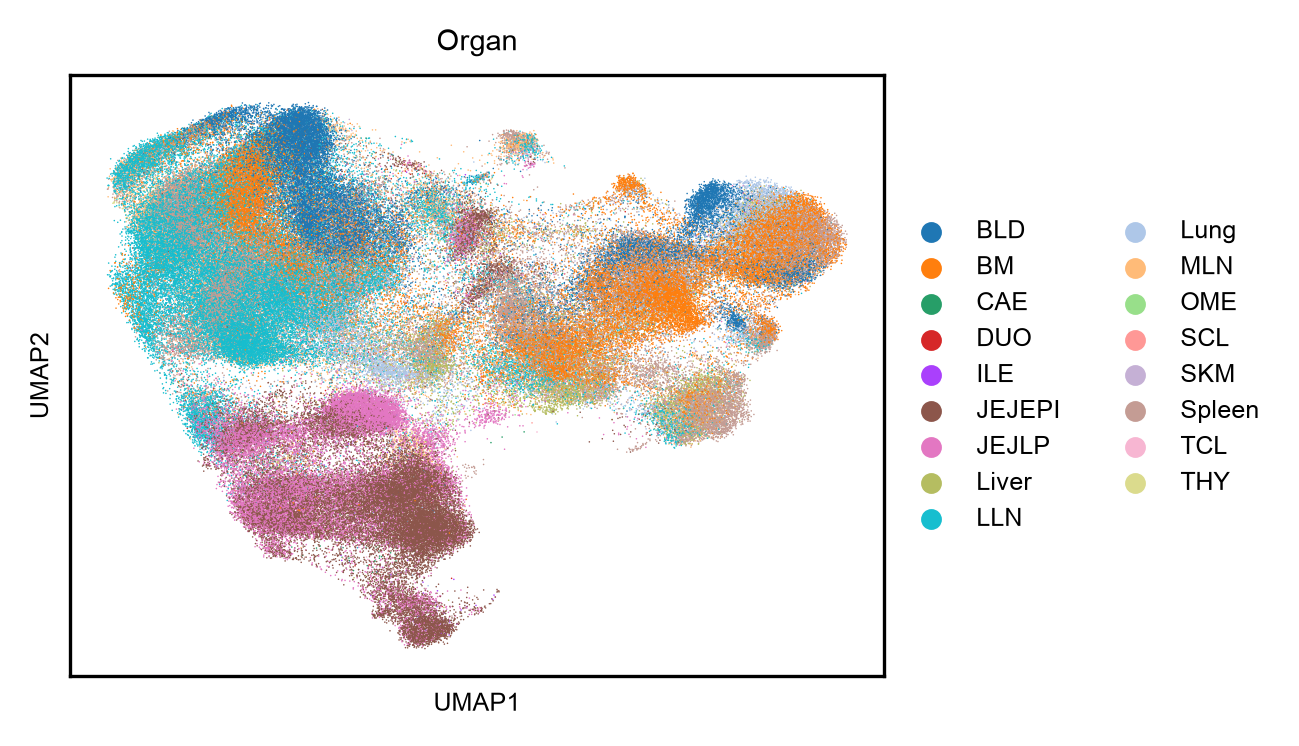

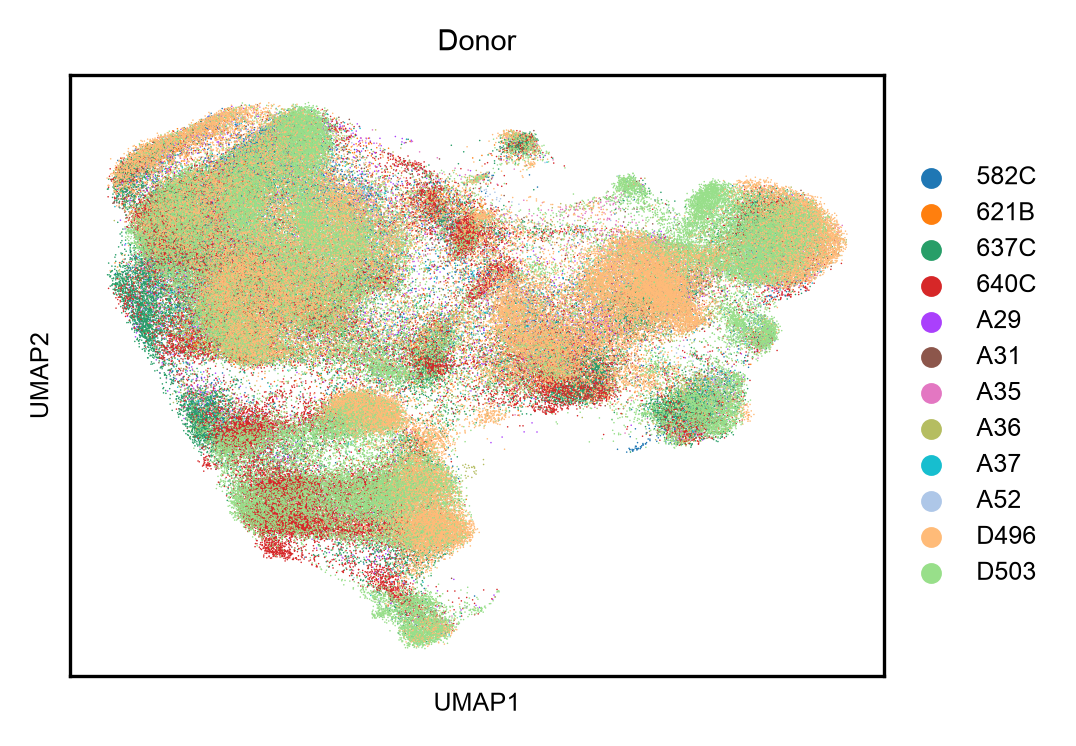

In [2]:
# calculate hvg genes
sc.pp.highly_variable_genes(adata, batch_key="Donor")
# print number of hvg genes
print(f"Number of highly variable genes: {np.sum(adata.var['highly_variable'])}")

# calculate pca
sc.tl.pca(adata, random_state=0)
# Get PCs from the AnnData object
pcs = adata.obsm["X_pca"]
print(pcs.shape)  # (n_cells, n_pcs)

# Run Harmony on the PCA embedding
harmony_out = hm.run_harmony(pcs, adata.obs, "Donor")

# Store corrected PCs back in the AnnData object
adata.obsm["X_pca_harmony"] = harmony_out.Z_corr

# compute 2d umap based on harmony integrated pca
sc.pp.neighbors(adata, use_rep="X_pca_harmony", random_state=0)
sc.tl.umap(adata, random_state=0)
sc.pl.umap(adata, color=["Organ"], wspace=0.4, show=True)
sc.pl.umap(adata, color=["Donor"], wspace=0.4, show=True)

# remove ribosmoal, mitochondrial genes etc..
adata.var.loc[
    adata.var_names.str.startswith(("RPS", "RPL", "MT-", "HSP", "HLA")),
    "highly_variable",
] = False

# save processed adata
adata.write_h5ad(path_data + "t-cells_processed.h5ad")

#Plot umap and color by tissue and cell type
adata_D503 = adata[adata.obs['Donor'] == '637C']
#only keep tissues with more than 100 cells
organs_to_keep = adata_D503.obs['Organ'].value_counts()[adata_D503.obs['Organ'].value_counts() > 100].index
adata_D503 = adata_D503[adata_D503.obs['Organ'].isin(organs_to_keep)]
#recalculate pca
sc.tl.pca(adata_D503, mask_var='highly_variable', n_comps=50)
sc.pp.neighbors(adata_D503, n_neighbors=15, n_pcs=50)
sc.tl.umap(adata_D503, min_dist=0.5, spread=1.0, random_state=42)
sc.pl.umap(adata_D503, color=['Organ', 'Manually_curated_celltype'], wspace=0.3)
print(adata_D503.obs['Organ'].value_counts())

### Use CellVADIS

In [3]:
# load processed adata
# Cells for calculating HVGs, PCA and UMAP just need to be calculated once, so we can load the processed adata for further analysis
adata = ad.read_h5ad(path_data + "t-cells_processed.h5ad")
source_name = "BLD"

adata_OT = adata.copy()
organs_to_keep = (
    adata_OT.obs["Organ"]
    .value_counts()[adata_OT.obs["Organ"].value_counts() > 1000]
    .index
)
# Only keep organs with more than 1000 cells
adata_OT = adata_OT[adata_OT.obs["Organ"].isin(organs_to_keep)]


def obs_key_wise_subsampling(adata, obs_keys, N, random_state=0):
    """
    Subsample to exactly N cells per group defined by obs_keys.
    Example: obs_keys=["timepoint", "location"] -> N cells for each (timepoint, location).
    """
    if isinstance(obs_keys, str):
        obs_keys = [obs_keys]

    group_sizes = adata.obs.groupby(obs_keys).size()
    too_small = group_sizes[group_sizes < N]
    if len(too_small) > 0:
        print("Subsample size to large, using minimum group size of", too_small.min())
        N = too_small.min()

    rng = np.random.default_rng(random_state)
    sampled_indices = []

    for _, df_group in adata.obs.groupby(obs_keys):
        # except BLD, where we subsample to 50k cells
        if "BLD" in df_group[obs_keys[0]].values:
            if len(df_group) < 50000:
                sampled_indices.append(df_group.index.to_numpy())
                continue
            else:
                sampled_indices.append(
                    rng.choice(df_group.index.to_numpy(), size=10000, replace=False)
                )
                continue
        sampled_indices.append(
            rng.choice(df_group.index.to_numpy(), size=N, replace=False)
        )

    selection = np.concatenate(sampled_indices)
    return adata[selection].copy()


adata_OT = obs_key_wise_subsampling(adata_OT, ["Organ"], 5000, random_state=0)

print(adata_OT.obs["Organ"].value_counts())
# subsample to 75%
# sc.pp.subsample(adata_OT, fraction=0.75, random_state=42)
mask_source = adata_OT.obs["Organ"] == source_name
mask_target = adata_OT.obs["Organ"] != source_name

data_source = adata_OT[mask_source].obsm["X_pca_harmony"].copy()
data_target = adata_OT[mask_target].obsm["X_pca_harmony"].copy()
target_locations = adata_OT[mask_target].obs["Organ"].values

# target_names are all except source_name
target_names = adata_OT.obs["Organ"].unique().tolist()
target_names.remove(source_name)
print("Target names:", target_names)

if use_stitchOT:
    fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Stitch_OT(
        data_source.astype(np.float64),
        data_target.astype(np.float64),
        target_locations,
        target_names,
        tau_a=0.5,
        subsample_non_blood=True,
        rescale_OT_plans=True,
        ignore_warnings=False,
        random_seed=42,
        cost_scaling="median",
        epsilon=0.005,
    )

else:
    print("Using Joint OT")
    fate_matrix, coupling_matrix, OT_plan, selected_target_mask = Joint_OT(
        data_source.astype(np.float64),
        data_target.astype(np.float64),
        target_locations,
        target_names,
        tau_b=0.5,
        subsample_non_blood=True,
        ignore_warnings=False,
        random_seed=42,
        cost_scaling="median",
        epsilon=0.005,
    )

# Plot fate matrix as stacked bar plot, with one bar per sample, colored by location

/tmp/ipykernel_139272/4038868623.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_sizes = adata.obs.groupby(obs_keys).size()
/tmp/ipykernel_139272/4038868623.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, df_group in adata.obs.groupby(obs_keys):


Organ
BLD       20333
BM         5000
JEJEPI     5000
JEJLP      5000
Liver      5000
LLN        5000
Lung       5000
MLN        5000
Spleen     5000
Name: count, dtype: int64
Target names: ['BM', 'JEJEPI', 'JEJLP', 'Liver', 'LLN', 'Lung', 'MLN', 'Spleen']


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/ot/unbalanced/_sinkhorn.py:736: UserWarning: If reg_type = entropy, then the matrix c is overwritten by the one matrix.
  warnings.warn(


### Plot UMAP of blood cells colored by dominant fate and with individual resultion for a subsample of blood cells

In [4]:
adata_blood = adata_OT[mask_source].copy()
sc.pp.neighbors(adata_blood, n_neighbors=30)
sc.tl.umap(adata_blood, min_dist=0.9, spread=0.9, random_state=42)
data_source_embedded = adata_blood.obsm["X_umap"].copy()


dominant_fate = np.argmax(fate_matrix, axis=1)
dominant_fate_names = [target_names[i] for i in dominant_fate]
plt.figure(figsize=(3.2, 3.2, "cm"), layout="constrained")
plt.scatter(
    data_source_embedded[:, 0],
    data_source_embedded[:, 1],
    c=[tissue_colors[tissue] for tissue in dominant_fate_names],
    s=0.35,
    edgecolor=None,
    alpha=0.9,
    linewidth=0,
    rasterized=True,
)
plt.xticks([])
plt.yticks([])
# remove borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
plt.savefig(figure_path + "dominant_fate_umap_.pdf", dpi=600)
plt.close()


# plot fate probabilities as pie charts on umap
fig, ax = plt.subplots(figsize=(3.2, 3.2, "cm"), layout="constrained")

plot_fate_probabilities_with_pie_charts(
    ax=ax,
    data_df=pd.DataFrame(data_source_embedded, columns=["UMAP1", "UMAP2"]),
    probability_df=pd.DataFrame(fate_matrix, columns=target_names),
    entropy_fade=False,
    background=40,
    outline=0,
    colors=[tissue_colors[tissue] for tissue in target_names],
    s=500,
    n_cells_to_plot=100,
    # locations=adata_blood.obs['photoconverted'].values,
    plot_legend=False,
)


plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["bottom"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
plt.xticks([])
plt.yticks([])
plt.savefig(figure_path + "fate_probabilities_pie_chart_umap_.pdf", dpi=600)
plt.close()

# create a legend and store seperately as pdf for later use


fig, ax = plt.subplots(figsize=(7, 1.6, "cm"), layout="constrained")
legend_elements = [
    Patch(color=tissue_colors[loc], label=f"{loc}")
    for i, loc in enumerate(target_names)
]
ax.legend(handles=legend_elements, title="Fate", ncol=4)
ax.axis("off")
plt.savefig(
    figure_path + "fate_legend.pdf",
    transparent=True,
)
plt.close()

### Plot tissue-specific transition proportions

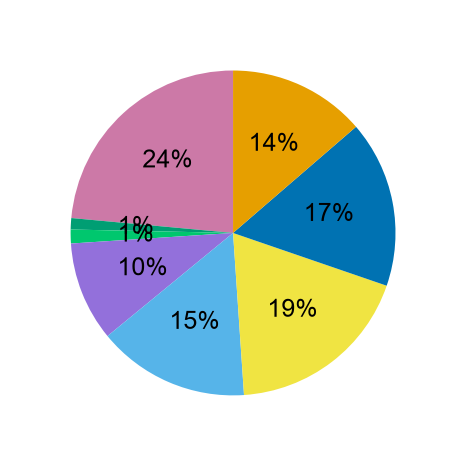

In [5]:
dominant_fate_proportions = np.sum(fate_matrix, axis=0) / np.sum(fate_matrix)

# Plot 2: Pie chart of dominant fates
fig, ax = plt.subplots(figsize=(3.65, 3.65, "cm"), layout="constrained")
colors = [tissue_colors[tissue] for tissue in target_names]
ax.pie(
    dominant_fate_proportions,
    autopct="%1.0f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.6,
)
plt.savefig(figure_path + "dominant_fate_pie_chart.pdf")
plt.show()

### Heatmap with the average fates per celltype

['Spleen', 'BM', 'MLN', 'LLN', 'JEJEPI', 'JEJLP', 'Liver', 'Lung']


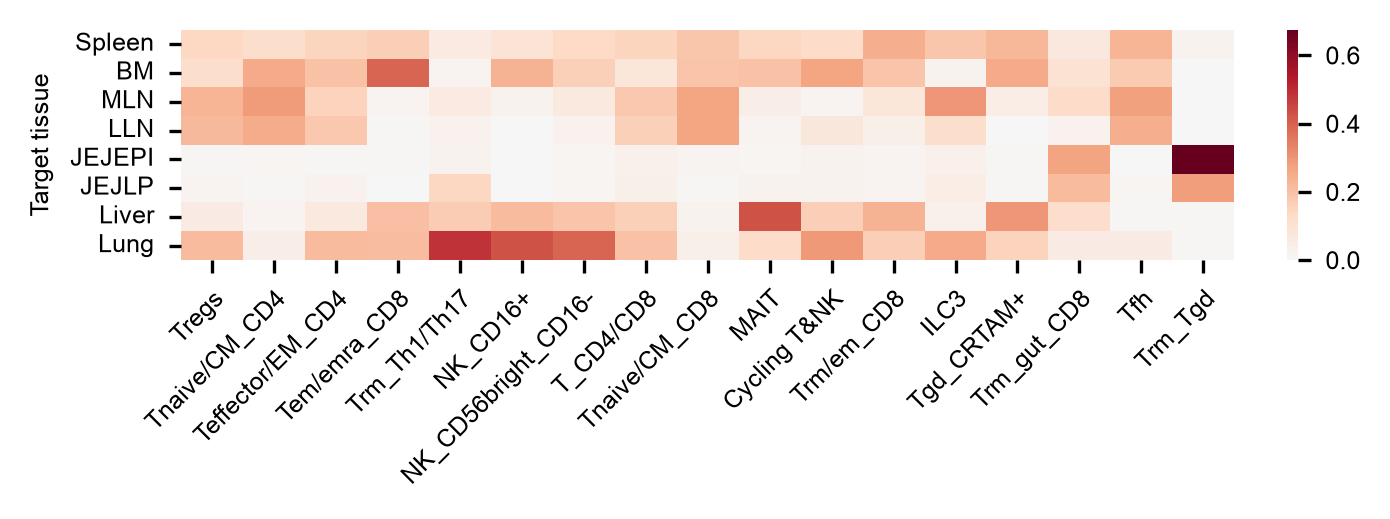

In [6]:
import seaborn as sns

avg_fate_per_celltype = {}
for celltype in adata_blood.obs["Manually_curated_celltype"].unique():
    mask_celltype = adata_blood.obs["Manually_curated_celltype"] == celltype
    avg_fate_per_celltype[celltype] = np.mean(fate_matrix[mask_celltype], axis=0)

# Convert the dictionary to a DataFrame for easier plotting
avg_fates = pd.DataFrame(avg_fate_per_celltype)
# set index to target_names
avg_fates.index = target_names
# change order of rows to  SPL, BMA, MLN, LLN, JEJEPI, JEJLP, LIV, LNG
desired_order = ["Spleen", "BM", "MLN", "LLN", "JEJEPI", "JEJLP", "Liver", "Lung"]
avg_fates = avg_fates.loc[desired_order]
# make row index categorical with the order of desired_order
avg_fates.index = pd.CategoricalIndex(
    avg_fates.index, categories=desired_order, ordered=True
)
print(avg_fates.index.tolist())
# Plot the heatmap
plt.figure(figsize=(11.5, 4.1, "cm"), layout="constrained")
sns.heatmap(avg_fates, annot=False, cmap="RdBu_r", center=0)  #
# plt.title('Average Fates per Cell Type')
# rotate xticks
plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
plt.ylabel("Target tissue")
# plt.yticks(ticks=np.arange(len(target_names))+0.5, labels=target_names, rotation=45, ha='right')
# plt.xlabel('Cell Type')
plt.savefig(figure_path + "average_fates_per_celltype.pdf")

In [7]:
# how many cells in blood are there for each celltype
for celltype in adata_OT.obs["Manually_curated_celltype"].unique():
    count = np.sum(
        (adata_OT.obs["Organ"] == "BLD")
        & (adata_OT.obs["Manually_curated_celltype"] == celltype)
    )
    print(f"Number of {celltype} cells in BLD: {count}")

Number of Tregs cells in BLD: 798
Number of Tnaive/CM_CD4 cells in BLD: 6609
Number of Teffector/EM_CD4 cells in BLD: 4331
Number of Tem/emra_CD8 cells in BLD: 1983
Number of Trm_Th1/Th17 cells in BLD: 35
Number of NK_CD16+ cells in BLD: 3539
Number of NK_CD56bright_CD16- cells in BLD: 445
Number of T_CD4/CD8 cells in BLD: 270
Number of Tnaive/CM_CD8 cells in BLD: 1182
Number of MAIT cells in BLD: 107
Number of Cycling T&NK cells in BLD: 215
Number of Trm/em_CD8 cells in BLD: 635
Number of ILC3 cells in BLD: 15
Number of Tgd_CRTAM+ cells in BLD: 47
Number of Trm_gut_CD8 cells in BLD: 9
Number of Tfh cells in BLD: 111
Number of Trm_Tgd cells in BLD: 2
Number of Tnaive/CM_CD4_activated cells in BLD: 0


### Find trafficking signatures by correlating genes with fate probability

In [8]:
from scipy.stats import spearmanr

# Correlate source-cell gene expression with a chosen target-fate probability
# and return a CellRank-style summary with effect size, p-value and 95% CI.
source_mask = adata_OT.obs["Organ"] == source_name
source_gene_expr = adata_OT.X.todense()[source_mask]
source_gene_expr = np.asarray(source_gene_expr)


def corr_with_ci(x, y):
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if x.size < 4 or np.allclose(x, x[0]) or np.allclose(y, y[0]):
        return np.nan, np.nan, np.nan, np.nan

    # corr, pvalue = pearsonr(x, y)
    # use spearman instead
    corr, pvalue = spearmanr(x, y)
    z = np.arctanh(corr)
    se = 1 / np.sqrt(x.size - 3)
    ci_low = np.tanh(z - 1.96 * se)
    ci_high = np.tanh(z + 1.96 * se)
    return corr, pvalue, ci_low, ci_high


corr_rows = []
for target in target_names:
    fate_vector = fate_matrix[:, target_names.index(target)]
    for gene in adata_OT.var_names[adata_OT.var["highly_variable"]]:
        gene_idx = adata_OT.var_names.get_loc(gene)
        gene_expr = source_gene_expr[:, gene_idx]
        corr, pvalue, ci_low, ci_high = corr_with_ci(gene_expr, fate_vector)
        corr_rows.append(
            {
                "gene": gene,
                "target": target,
                "correlation": corr,
                "pvalue": pvalue,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "abs_correlation": np.abs(corr),
            }
        )

corr_df = pd.DataFrame(corr_rows).dropna(subset=["correlation"]).reset_index(drop=True)
corr_df = corr_df.sort_values(["correlation"], ascending=[False]).reset_index(drop=True)
# exclude genes that are mitochondrial, ribosomoal or other generic rna genes
corr_df = corr_df[
    ~corr_df["gene"].str.startswith(("MT-", "RPL", "RPS", "MALAT1", "NEAT1"))
]
print(corr_df.head(20))
# plot top 20 genes with highest absolute correlation

     gene  target  correlation  pvalue    ci_low   ci_high  abs_correlation
0     LTB     LLN     0.494413     0.0  0.483957  0.504729         0.494413
1    CCR7     LLN     0.492719     0.0  0.482240  0.503058         0.492719
2    CCR7     MLN     0.483551     0.0  0.472949  0.494013         0.483551
3    IL7R     LLN     0.483359     0.0  0.472755  0.493824         0.483359
4    NKG7   Liver     0.448692     0.0  0.437645  0.459603         0.448692
5    CCL5   Liver     0.447568     0.0  0.436508  0.458493         0.447568
6    GZMA   Liver     0.444905     0.0  0.433813  0.455863         0.444905
7     LTB     MLN     0.436439     0.0  0.425245  0.447500         0.436439
8    CST7   Liver     0.430714     0.0  0.419451  0.441843         0.430714
9    CCR7  JEJEPI     0.417974     0.0  0.406565  0.429254         0.417974
10  SOCS3     LLN     0.414468     0.0  0.403019  0.425788         0.414468
11   CST7    Lung     0.412168     0.0  0.400693  0.423514         0.412168
12   IL7R   

In [9]:
# do barplot for top 15 genes for each target
for target in target_names:
    # sort by abs_correlation and take top 25 genes
    corr_df_target = (
        corr_df[corr_df["target"] == target]
        .sort_values(by="correlation", ascending=False)
        .head(20)
    )
    plt.figure(figsize=(2.8, 4.8, "cm"), layout="constrained")

    # add lines from gene name to correlation value
    k = 19
    for i, row in corr_df_target.iterrows():
        plt.plot(
            [0, row["correlation"]],
            [k, k],
            color="dimgray",
            linewidth=0.8,
            alpha=1,
            zorder=1,
        )
        k -= 1
    plt.scatter(
        corr_df_target["correlation"],
        np.arange(len(corr_df_target))[::-1],
        color=tissue_colors[target],
        zorder=2,
    )
    # scatter plot should be above the lines
    plt.yticks(
        np.arange(len(corr_df_target)), corr_df_target["gene"][::-1], fontsize=5.5
    )
    plt.title(f"{target}", pad=3)
    # plt.xlabel('Correlation')
    # plt.ylabel('Gene')
    plt.xlim(0.0, 0.56)
    # remove top and right borders
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.gca().set_position([0.5, 0.09, 0.45, 0.84])
    plt.savefig(figure_path + f"top_genes_correlation_{target}.pdf")
    plt.close()

### Visually look for homing niches in UMAP projection

In [10]:
import umap

# Compute a Umap of tissue cells
for tissue in target_names:
    # extract tissue cells from adata_OT
    colon_cells = data_target[selected_target_mask][
        target_locations[selected_target_mask] == tissue
    ]
    umap_colon = umap.UMAP(
        n_neighbors=30, min_dist=0.3, spread=1, random_state=42
    ).fit_transform(colon_cells)
    # plot umap embedding of colon cells
    fig, ax = plt.subplots(figsize=(2.2, 3.4, "cm"), layout="constrained")
    ax.scatter(
        umap_colon[:, 0],
        umap_colon[:, 1],
        c="darkgray",
        s=1.5,
        alpha=0.6,
        edgecolor=None,
        linewidth=0,
        rasterized=True,
    )
    # dont show the axes
    ax.set_xticks([])
    ax.set_yticks([])
    # now compute the average coordinates of all blood cells that have a fate probability greater than 0.35 for colon and plot this point on the umap
    blood_cells_fate_prob = fate_matrix[:, target_names.index(tissue)]
    # compute the average coordinates of these blood cells by multiplying the coupling matrix with the colon cells coordinates
    blood_cells_high_fate_coupling = coupling_matrix[blood_cells_fate_prob > 1 / 3, :][
        :, target_locations[selected_target_mask] == tissue
    ]

    # Normalize the selected weights so they sum to 1 for each blood cell.
    # Otherwise the weighted sum is a scaled affine combination and can fall outside the convex hull of the tissue coordinates.
    row_sums = blood_cells_high_fate_coupling.sum(axis=1, keepdims=True)
    normalized_weights = np.divide(
        blood_cells_high_fate_coupling,
        row_sums,
        out=np.zeros_like(blood_cells_high_fate_coupling),
        where=row_sums > 0,
    )

    blood_cells_high_fate_projected = normalized_weights @ umap_colon
    print(
        "blood_cells_high_fate_projected shape:", blood_cells_high_fate_projected.shape
    )

    ax.scatter(
        blood_cells_high_fate_projected[:, 0],
        blood_cells_high_fate_projected[:, 1],
        c=tissue_colors[tissue],
        s=3,
        label="Blood cells projected to " + tissue,
        alpha=0.95,
        edgecolor=None,
        linewidth=0,
        rasterized=True,
    )
    # ax.legend(fontsize=6)
    # dont show the axes
    ax.set_xticks([])
    ax.set_yticks([])
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.gca().spines["bottom"].set_visible(False)
    plt.gca().spines["left"].set_visible(False)
    plt.savefig(figure_path + "umap_" + tissue + "_with_blood_projection_.pdf", dpi=600)
    plt.close()

    # color by CCR7 expression
    # fig, ax = plt.subplots(figsize=(3, 3, "cm"), layout='constrained')
    # gene_expressions = adata_OT.X[:, adata.var_names.get_loc('CCR7')].todense()[adata_OT.obs['Organ'] != source_name][selected_target_mask][target_locations[selected_target_mask] == tissue]
    # gene_expressions =np.asarray(gene_expressions).flatten()
    # ax.scatter(umap_colon[:, 0], umap_colon[:, 1], c=gene_expressions, cmap='viridis', s=5, alpha=0.5)
    # ax.set_title('UMAP Embedding of ' + tissue + ' Cells colored by CCR7 expression')
    # ax.set_xticks([])
    # ax.set_yticks([])
    # plt.savefig(figure_path + 'umap_' + tissue + '_colored_by_CCR7_expression_.pdf', dpi=300)
    # plt.close()

/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (5755, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (109, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (196, 2)


... (6 outputs left out)

/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (3980, 2)


/home/wickerlw/Projects/OT_trafficking/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


blood_cells_high_fate_projected shape: (2742, 2)


### Quantify homing niches by correlating marginal weights with marker expressions of tissue cells

In [11]:
for tissue in target_names:
    tissue_mask = target_locations[selected_target_mask] == tissue
    # subset rows of OT_plan to only those that correspond to blood cells with dominant fate belonging to tissue
    # subset OT_plan to only those rows
    OT_plan_dominant = OT_plan[fate_matrix[:, target_names.index(tissue)] > 1 / 3, :]
    landing_mass_homing_score = OT_plan[:, tissue_mask].sum(axis=0)
    # correlate this with the expression of every HVG
    gene_expressions = adata_OT.X[:, :].todense()[adata_OT.obs["Organ"] != source_name][
        selected_target_mask
    ][target_locations[selected_target_mask] == tissue, :]
    gene_expressions = np.asarray(gene_expressions)
    # only hvg
    gene_expressions = gene_expressions[:, adata.var["highly_variable"]]
    correlation_with_expression = np.array(
        [
            spearmanr(np.log(landing_mass_homing_score[:]), gene_expressions[:, i])[0]
            for i in range(np.sum(adata.var["highly_variable"][:]))
        ]
    )
    # set nans to 0
    correlation_with_expression[np.isnan(correlation_with_expression)] = 0
    # only keep top 20 genes with highest absolute correlation
    top_20_genes_idx = np.argsort(np.abs(correlation_with_expression))[-15:]
    correlation_with_expression = correlation_with_expression[top_20_genes_idx]
    # plot as bar plot
    plt.figure(figsize=(6, 2.4, "cm"), layout="constrained")
    plt.axhline(0, color="dimgray", linestyle="solid", linewidth=0.8, alpha=1)
    plt.bar(
        adata.var_names[adata.var["highly_variable"]][top_20_genes_idx[::-1]],
        correlation_with_expression[::-1],
        color=tissue_colors[tissue],
    )
    plt.xticks(rotation=45, fontsize=6, ha="right", rotation_mode="anchor")
    plt.ylim(-0.6, 0.6)
    plt.yticks([-0.5, 0, 0.5])
    # plot title on right side of the plot 90 degrees rotated
    plt.text(
        0.85,
        0.9,
        tissue,
        rotation=0,
        fontsize=7,
        va="center",
        ha="center",
        transform=plt.gca().transAxes,
    )
    plt.gca().set_position([0.11, 0.5, 0.88, 0.485])
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    # ax.set_xlabel('Marker')
    # ax.set_ylabel('Correlation')
    plt.savefig(figure_path + "marginal_mass_homing_correlation_" + tissue + ".pdf")
    plt.close()

/tmp/ipykernel_139272/1792500623.py:16: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(np.log(landing_mass_homing_score[:]), gene_expressions[:, i])[0]


In [12]:
correlation_with_expression

array([-0.33929881,  0.3489505 , -0.35146665, -0.35184786, -0.35417761,
       -0.35800301, -0.3584299 , -0.36879532,  0.37247818,  0.37868242,
        0.37959099, -0.38276899, -0.38590827, -0.4414224 , -0.45916422])